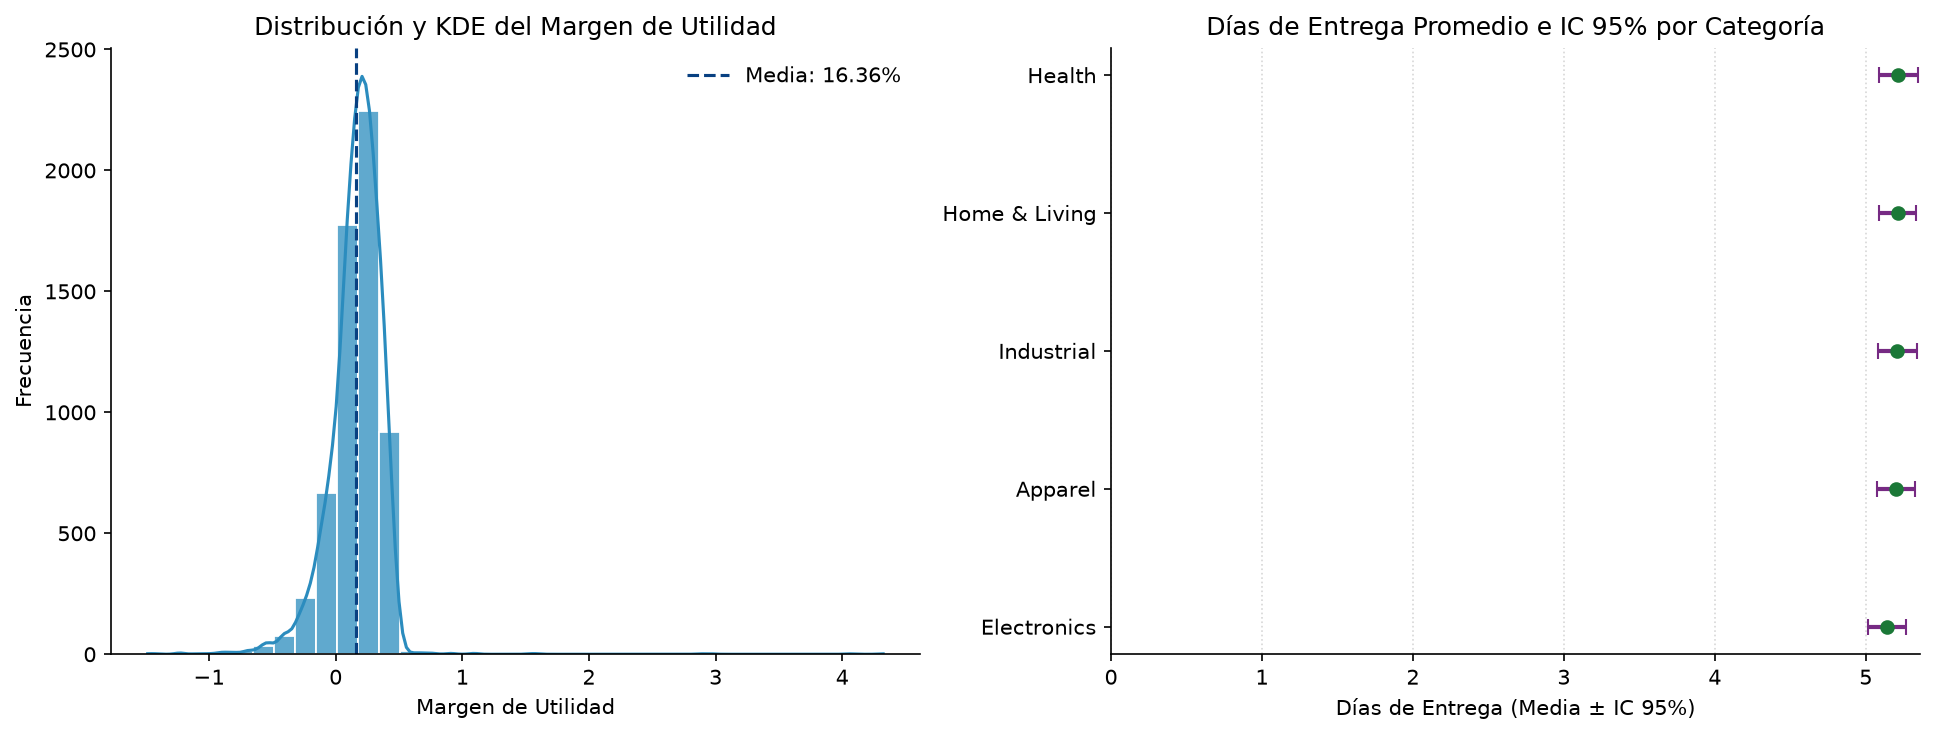

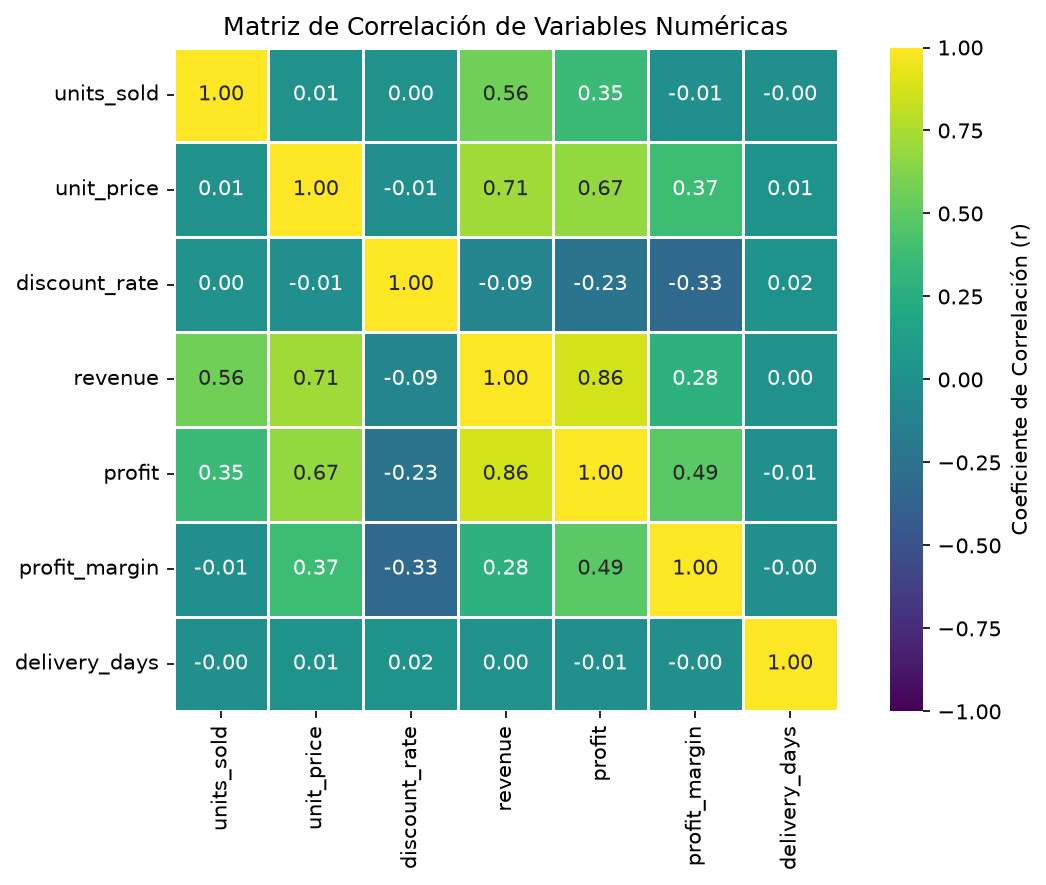

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

# Asegurar que exista la carpeta exports para guardar gráficos
os.makedirs("../exports", exist_ok=True)

# Configuración visual limpia (sin bordes superiores/derechos innecesarios)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# Cargar dataset limpio generado en el paso anterior
df = pd.read_csv("../data/processed/clean_enterprise_data.csv")
df["order_date"] = pd.to_datetime(df["order_date"])

# ==========================================================
# 1. DISTRIBUCIÓN + KDE + INTERVALO DE CONFIANZA (95% CI)
# ==========================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histograma y KDE de margen de utilidad
sns.histplot(
    data=df, x="profit_margin", bins=35, kde=True,
    color="#2b8cbe", edgecolor="white", alpha=0.75, ax=axes[0]
)
mean_margin = df["profit_margin"].mean()
axes[0].axvline(
    mean_margin, color="#084081", linestyle="--", linewidth=1.5,
    label=f"Media: {mean_margin:.2%}"
)
axes[0].set_title("Distribución y KDE del Margen de Utilidad")
axes[0].set_xlabel("Margen de Utilidad")
axes[0].set_ylabel("Frecuencia")
axes[0].legend(frameon=False)

# Media e Intervalo de Confianza al 95% de días de entrega por categoría
cat_stats = []
for cat, grp in df.groupby("category"):
    vals = grp["delivery_days"].dropna()
    m = vals.mean()
    sem = stats.sem(vals)
    ci_low, ci_high = stats.t.interval(0.95, df=len(vals) - 1, loc=m, scale=sem)
    cat_stats.append((cat, m, m - ci_low, ci_high - m))

stats_df = pd.DataFrame(
    cat_stats, columns=["category", "mean", "err_low", "err_high"]
).sort_values("mean", ascending=True)

y_pos = np.arange(len(stats_df))
axes[1].errorbar(
    x=stats_df["mean"],
    y=y_pos,
    xerr=[stats_df["err_low"], stats_df["err_high"]],
    fmt="o",
    color="#1b7837",
    ecolor="#762a83",
    elinewidth=2,
    capsize=4,
)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(stats_df["category"])
axes[1].set_xlim(left=0)  # Línea base en 0
axes[1].set_title("Días de Entrega Promedio e IC 95% por Categoría")
axes[1].set_xlabel("Días de Entrega (Media ± IC 95%)")
axes[1].grid(axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("../exports/fig1_distribution_ci.png", dpi=300, bbox_inches="tight")
plt.show()

# ==========================================================
# 2. MATRIZ DE CORRELACIÓN (SEABORN HEATMAP - VIRIDIS)
# ==========================================================
num_cols = [
    "units_sold", "unit_price", "discount_rate",
    "revenue", "profit", "profit_margin", "delivery_days"
]
corr_matrix = df[num_cols].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Coeficiente de Correlación (r)"},
)
plt.title("Matriz de Correlación de Variables Numéricas")
plt.tight_layout()
plt.savefig("../exports/fig2_correlation_heatmap.svg", format="svg", bbox_inches="tight")
plt.savefig("../exports/fig2_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# ==========================================================
# 3. SCATTER / BUBBLE INTERACTIVO (PLOTLY -> .HTML)
# ==========================================================
sample_df = df.sample(min(1500, len(df)), random_state=42)

fig_scatter = px.scatter(
    sample_df,
    x="revenue",
    y="profit",
    size="units_sold",
    color="region",
    hover_data=["category", "sales_channel", "delivery_days"],
    title="Relación Ingresos vs. Utilidad por Región (Tamaño = Unidades Vendidas)",
    labels={"revenue": "Ingresos ($)", "profit": "Utilidad ($)", "units_sold": "Unidades"},
    color_discrete_sequence=px.colors.qualitative.Set2,
    template="plotly_white",
)
fig_scatter.write_html("../exports/fig3_scatter_interactive.html")
fig_scatter.show()

# ==========================================================
# 4. MAPA GEOESPACIAL INTERACTIVO (PLOTLY -> .HTML)
# ==========================================================
geo_summary = (
    df.groupby(["region", "country", "lat", "lon"], as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum"),
        avg_days=("delivery_days", "mean"),
    )
)

fig_geo = px.scatter_geo(
    geo_summary,
    lat="lat",
    lon="lon",
    size="total_revenue",
    color="total_profit",
    hover_name="country",
    hover_data=["region", "total_revenue", "total_profit", "avg_days"],
    color_continuous_scale="Viridis",
    title="Desempeño Geográfico: Ingresos (Tamaño) y Utilidad (Color)",
    template="plotly_white",
)
fig_geo.write_html("../exports/fig4_geo_map.html")
fig_geo.show()